In [3]:
#charger et nettoyer

import pandas as pd

# Charger CSV
df = pd.read_csv("../data/telco_churn.csv")

# TotalCharges convertit en nbr
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

# Remplacer les valeurs manquantes par 0
df["TotalCharges"] = df["TotalCharges"].fillna(0)

print(df.shape)
print(df["TotalCharges"].isna().sum(), "valeurs manquantes")

(7043, 21)
0 valeurs manquantes


In [4]:
#imports et standardisation
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

RANDOM_STATE = 42

X2 = df[["tenure", "MonthlyCharges"]]
scaler2 = StandardScaler()
X2_scaled = scaler2.fit_transform(X2)
print(X2_scaled.mean(axis=0).round(3), X2_scaled.std(axis=0).round(3))

[-0. -0.] [1. 1.]


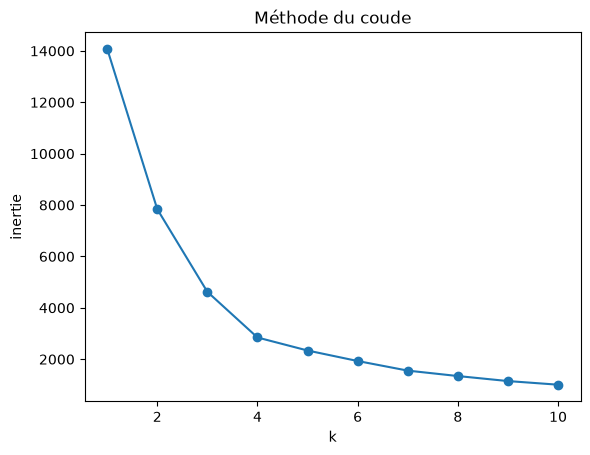

In [5]:
#méthode du coude
ks = range(1, 11)
inerties = []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X2_scaled)
    inerties.append(km.inertia_)

plt.plot(ks, inerties, marker="o")
plt.xlabel("k")
plt.ylabel("inertie")
plt.title("Méthode du coude")
plt.show()

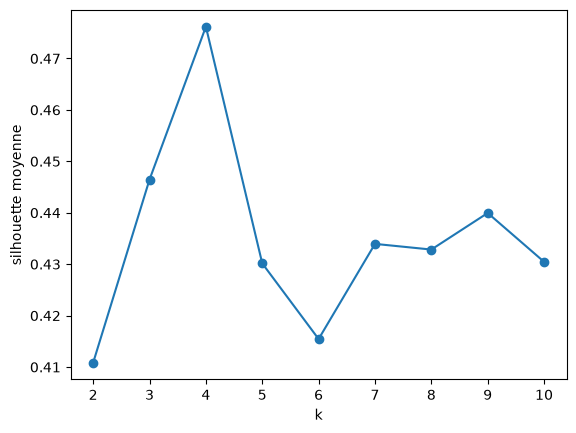

meilleur k : 4


In [6]:
#silhouette

ks_sil = range(2, 11)
silhouettes = []
for k in ks_sil:
    labels = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit_predict(X2_scaled)
    silhouettes.append(silhouette_score(X2_scaled, labels))

plt.plot(ks_sil, silhouettes, marker="o")
plt.xlabel("k")
plt.ylabel("silhouette moyenne")
plt.show()
print("meilleur k :", ks_sil[int(np.argmax(silhouettes))])

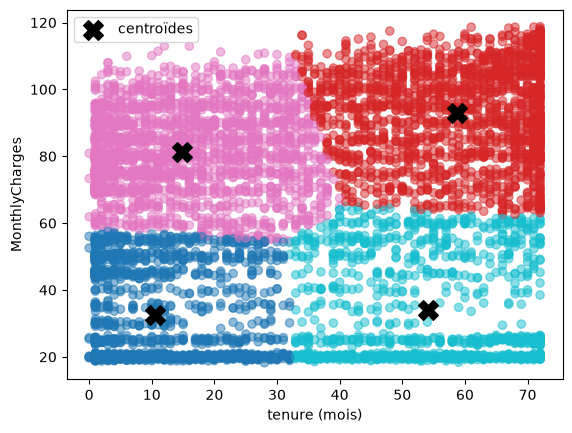

In [10]:
#K-Means et visualisation
K = 4
kmeans2 = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE)
df["cluster"] = kmeans2.fit_predict(X2_scaled)

# Centres des groupes en unités d'origine (mois, dollars par mois)
centres = scaler2.inverse_transform(kmeans2.cluster_centers_)

plt.scatter(df["tenure"], df["MonthlyCharges"], c=df["cluster"], cmap="tab10", alpha=0.5)
plt.scatter(centres[:, 0], centres[:, 1], c="black", marker="X", s=200, label="centroïdes")
plt.xlabel("tenure (mois)")
plt.ylabel("MonthlyCharges")
plt.legend()
plt.show()

In [ ]:
#profil des groupes
df["depart"] = df["Churn"] == "Yes"

profil = (
    df.groupby("cluster")
    .agg(effectif=("customerID", "size"),
         tenure=("tenure", "mean"),
         prix_mensuel=("MonthlyCharges", "mean"),
         taux_depart=("depart", "mean"))
    .round(2)
)
display(profil)

# Type de contrat dans chaque groupe 
pd.crosstab(df["cluster"], df["Contract"], normalize="index").round(2)

,effectif,tenure,prix_mensuel,taux_depart
cluster,,,,
0,1732,10.49,32.47,0.25
1,1952,58.75,93.02,0.16
2,2204,14.81,81.22,0.49
3,1155,54.12,34.03,0.05


Contract,Month-to-month,One year,Two year
cluster,,,
0,0.73,0.17,0.10
1,0.27,0.31,0.42
2,0.87,0.11,0.02
3,0.15,0.29,0.56


In [11]:
#enregistrer
import os
import joblib

# Dossier models
os.makedirs("../models", exist_ok=True)

# scaler / K-Means
joblib.dump(scaler2, "../models/scaler.joblib")
joblib.dump(kmeans2, "../models/kmeans.joblib")

# groupe / client
df.to_csv("../data/telco_clusters.csv", index=False)

print(os.listdir("../models"))

['clustering.joblib', 'kmeans.joblib', 'scaler.joblib']
